In [1]:
from torchvision import datasets, transforms

transform = transforms.Compose([transforms.ToTensor()])
train_data = datasets.CIFAR10(root="~/.cache/", transform=transform, train=True, download=True)
test_data = datasets.CIFAR10(root="~/.cache/", transform=transform, train=False)
print(train_data[0][0].shape)
print(test_data[0][0].dtype)

Files already downloaded and verified
torch.Size([3, 32, 32])
torch.float32


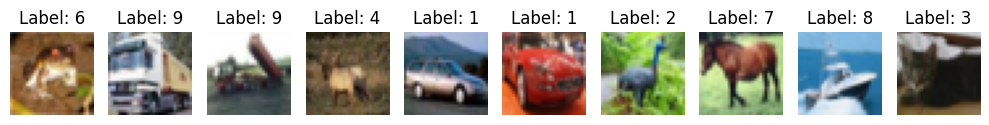

In [2]:
import matplotlib.pyplot as plt

# 遍历前10张图片
fig, axes = plt.subplots(1, 10, figsize=(10, 2))  # 1行10列的子图
for i in range(10):
    image, label = train_data[i]
    ax = axes[i]  # 获取当前子图
    ax.imshow(image.permute(1, 2, 0))
    ax.set_title(f'Label: {label}')  # 显示标签
    ax.axis('off')  # 关闭坐标轴

plt.tight_layout()  # 自动调整子图间的间距
plt.show()

In [3]:
import torch
import torch.nn as nn
import torch.nn.functional as F

from quantizer import VectorQuantizer


class Encoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=4, stride=2, padding=1),   # (32x32) → (16x16)
            nn.ReLU(),
            nn.Conv2d(16, 32, kernel_size=4, stride=2, padding=1),  # (16x16) → (8x8)
            nn.ReLU(),
            nn.Conv2d(32, 64, kernel_size=4, stride=2, padding=1), # (8x8) → (4x4)
            nn.ReLU()
        )

    def forward(self, x):
        return self.encoder(x)  # 输出: (B, 64, 4, 4)

class Decoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(64, 32, kernel_size=4, stride=2, padding=1),  # (4x4) → (8x8)
            nn.ReLU(),
            nn.ConvTranspose2d(32, 16, kernel_size=4, stride=2, padding=1),   # (8x8) → (16x16)
            nn.ReLU(),
            nn.ConvTranspose2d(16, 3, kernel_size=4, stride=2, padding=1),    # (16x16) → (32x32)
            nn.Sigmoid()  # 输出范围控制在 [0,1]，适合图像重建
        )

    def forward(self, x):
        return self.decoder(x)  # 输出: (B, 3, 32, 32)



class VQVAE(nn.Module):
    def __init__(self, n_e, e_dim, norm_weight=True, beta=1.):
        super().__init__()
        self.encoder = Encoder()
        self.quantizer = VectorQuantizer(n_e, e_dim, norm_weight, beta)
        self.decoder = Decoder()

    def forward(self, x: torch.Tensor):
        # (B, C, H, W)
        z = self.encoder(x)
        z_q, indices, q_loss, codebook_usage = self.quantizer(z)
        x_q = self.decoder(z_q)

        return x_q, indices, q_loss, codebook_usage
    
    def encode(self, x: torch.Tensor):
        # (B, C, H, W)
        z = self.encoder(x)
        z_q, *_ = self.quantizer(z)
        return z_q
    
    def decode(self, z_q: torch.Tensor):
        # (B, C, H, W)
        x_q = self.decoder(z_q)
        return x_q

In [4]:
vqvae = VQVAE(n_e=512, e_dim=16)

x: torch.Tensor = train_data[0][0]
x = x.unsqueeze(0)  # 添加batch维度

x_q, indices, vq_loss, codebook_usage = vqvae(x) 
print(x_q.shape)
print(indices.shape) # use 16 tokens to encode one image
print(codebook_usage.shape)

z_q = vqvae.encode(x)
print(z_q.shape)



torch.Size([1, 3, 32, 32])
torch.Size([1, 64])
torch.Size([512])
torch.Size([1, 64, 4, 4])


In [6]:
from lpips import LPIPS

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

lipis_model = LPIPS().eval().to(device)
vqvae = VQVAE(n_e=512, e_dim=16, norm_weight=False).to(device)

dataloader = torch.utils.data.DataLoader(train_data, batch_size=128, shuffle=True, num_workers=8)
optimizer = torch.optim.Adam(vqvae.parameters(), lr=1e-3)
epochs = 50


vqvae.train()
for epoch in range(epochs):
    for img, _ in dataloader:
        img = img.to(device)

        x_q, _, q_loss, usage = vqvae(img)
        entropy = - torch.sum(usage * torch.log(usage + 1e-6)) # 直接对分布熵做约束，效果比L2 norm好多了...
        perception_loss = lipis_model(x_q, img).mean()
        loss = F.mse_loss(x_q, img) + q_loss + perception_loss + 0.001 * entropy

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

    if epoch == 0 or (epoch + 1) % 5 == 0:
        print(f"Epoch {epoch + 1}/{epochs}, Loss: {loss.item():.4f}")



loaded pretrained LPIPS loss from ~/.cache/vgg.pth
Epoch 1/50, Loss: 0.5003
Epoch 5/50, Loss: 0.3073
Epoch 10/50, Loss: 0.2800
Epoch 15/50, Loss: 0.2854
Epoch 20/50, Loss: 0.2758
Epoch 25/50, Loss: 0.2862
Epoch 30/50, Loss: 0.2781
Epoch 35/50, Loss: 0.2815
Epoch 40/50, Loss: 0.2830
Epoch 45/50, Loss: 0.2884
Epoch 50/50, Loss: 0.2700


[227 448 379 137 133 162  83 137 133  97 158 498 133 358 244 221 279 419
 121 119 134 506 163 293 343 255 176 404 140  12 489 324 397 349 362   4
  56 166 148 147 309 241 342 463  33 468 339 119 125 219 178 179 483 182
 489  44 380 241  83 356  53 387 489 356]


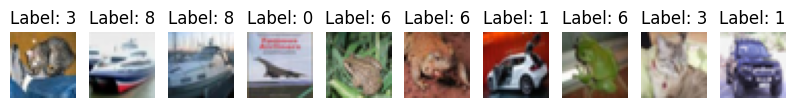

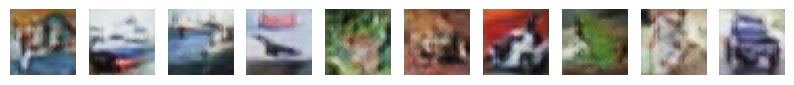

In [7]:
# 遍历前10张图片
x = torch.vstack([test_data[i][0].unsqueeze(0) for i in range(10)]).to(device)

x_q, ids, vq_loss, _ = vqvae(x)
x_q = x_q.cpu().detach()
x_p = vqvae.decode(vqvae.encode(x)).cpu().detach()

print(ids[0].cpu().numpy())

fig, axes = plt.subplots(1, 10, figsize=(10, 2))  # 1行10列的子图
for i in range(10):
    image, label = test_data[i]
    ax = axes[i]  # 获取当前子图
    ax.imshow(image.permute(1, 2, 0))
    ax.set_title(f'Label: {label}')  # 显示标签
    ax.axis('off')  # 关闭坐标轴

fig, axes = plt.subplots(1, 10, figsize=(10, 2))  # 1行10列的子图
for i in range(10):
    image, label = x_p[i], test_data[i][1]
    ax = axes[i]  # 获取当前子图
    ax.imshow(image.permute(1, 2, 0))
    ax.axis('off')  # 关闭坐标轴

tensor(1.1241e-06)
tensor(19)


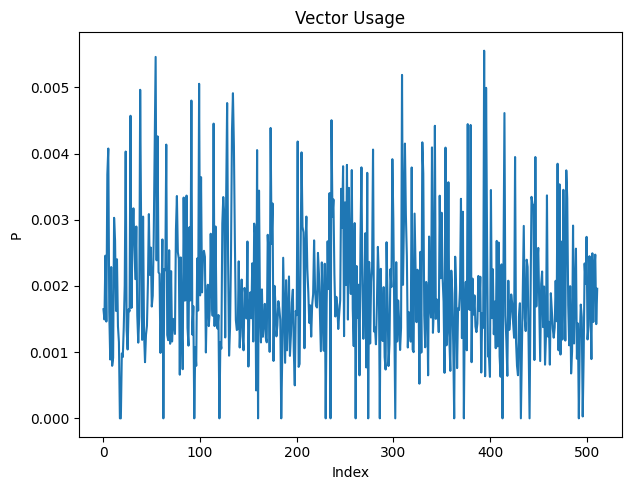

In [8]:
test_loader = torch.utils.data.DataLoader(test_data, batch_size=512, shuffle=False, num_workers=4)

vqvae.eval()
usage = 0
for img, _ in test_loader:
    img = img.to(device)

    _, _, _, u = vqvae(img)
    usage += u.cpu() * len(img)

usage /= len(test_data)

print(usage.var())
print(torch.sum(usage == 0.0))
plt.figure(figsize=(12, 5))

# 折线图
plt.subplot(1, 2, 1)
plt.plot(usage)
plt.title('Vector Usage')
plt.xlabel('Index')
plt.ylabel('P')


plt.tight_layout()
plt.show()